<a href="https://colab.research.google.com/github/PierreCr/Digital-Pathology/blob/main/Mini_project_in_Computational_Pathology_Part_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini-project in Computational Pathology - Part 2.
# Pierre Cordier, DVM, PhD, Dipl.ECVP.
# 11/10/2026.


In [ ]:
#19.0. Now introduce AI.
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [ ]:
#19.1. Now introduce AI.
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

# Load pretrained image encoder: ResNet-18
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Remove the final 1000-class classification layer
model.fc = torch.nn.Identity()

# Prepare for inference, not training
model.eval()

# Use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Use the preprocessing designed for these weights
preprocess = weights.transforms()

print("Device:", device)
print("Model ready")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Device: CPU
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]

Device: cpu
Model ready


Important aspects:

* weights=weights loads learned parameters; without it, you'd have a randomly initialized network.
* model.fc = torch.nn.Identity() replaces the final classification layer with an identity operation, exposing the
512 features instead of 1,000 class scores.
* model.eval() sets inference behavior, which matters for layers such as batch normalization.
* preprocess resizes and normalizes images in the way expected by these weights.


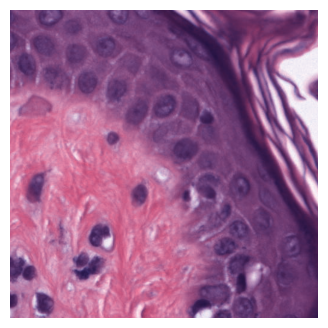

In [ ]:
#19.2. Run pretrained image encoder on 1 patch.

# Load 1 image
patch = Image.open("/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/CMU-1_patch_53_normed.png").convert("RGB")
plt.figure(figsize=(4, 4))
plt.imshow(patch)
plt.axis("off");

# Convert the image to a normalized tensor
image_tensor = preprocess(patch)

# Add a batch dimension: (3, 224, 224) -> (1, 3, 224, 224)
batch = image_tensor.unsqueeze(0).to(device)

with torch.inference_mode():
    embedding = model(batch)

embedding = embedding.cpu().numpy()

print("Embedding shape:", embedding.shape)
print("First 10 values:", embedding[0, :10])

In [ ]:
#19.3. Run pretrained image encoder on all patches.
patch_dir = Path("/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/")

image_paths = sorted([
  p for p in patch_dir.iterdir()
  if p.suffix.lower() in {".png", ".jpg", ".jpeg"}])

print("Number of patches:", len(image_paths))

if len(image_paths) == 0:
  raise ValueError("No images found. Check patch_dir.")

# Batch analysis
from torch.utils.data import Dataset, DataLoader

class PatchDataset(Dataset):
  def __init__(self, paths, transform):
    self.paths = paths
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, index):
    path = self.paths[index]

    with Image.open(path) as image:
      image = image.convert("RGB")
      tensor = self.transform(image)
    return tensor, str(path)

dataset = PatchDataset(image_paths, preprocess)

loader = DataLoader(
      dataset,
      batch_size=32,
      shuffle=False,
      num_workers=0)

all_embeddings = []
all_paths = []

with torch.inference_mode():
  for images, paths in loader:
    images = images.to(device)
    features = model(images)
    all_embeddings.append(features.cpu().numpy())
    all_paths.extend(paths)

embeddings = np.concatenate(all_embeddings, axis=0)
print("Embedding matrix:", embeddings.shape)

Embedding matrix: (96, 512)


In [ ]:
#19.4. Save the results.
output_dir = Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/")
output_dir.mkdir(parents=True, exist_ok=True)

# Embeddings
np.save(output_dir / "embeddings.npy", embeddings)

# Metadata table
metadata = pd.DataFrame({
  "patch_path": all_paths,
  "embedding_row": np.arange(len(all_paths))})

metadata.to_csv(output_dir / "patch_metadata.csv", index=False)

print("Saved embeddings and metadata.")

Saved embeddings and metadata.


In [ ]:
#20. Understand embeddings before classification.


# --
#Q45. What does one row represent?
#A45. Each row represents one patch.

#Q46. What does one column represent?
#A46. Each column represents a feature vector.

#Q47. Are the 512 features individually interpretable as "nucleus", "lymphocyte", "collagen", etc.? Be careful here.
#A47. No they do not directly mean "lymphocyte", "necrosis ", "nucleus". They are learned numerical features (features vectors).

PCA shape: (96, 3)
Explained variance ratio [0.22780308 0.07991    0.07167722]
Variance explained by three components: 0.379


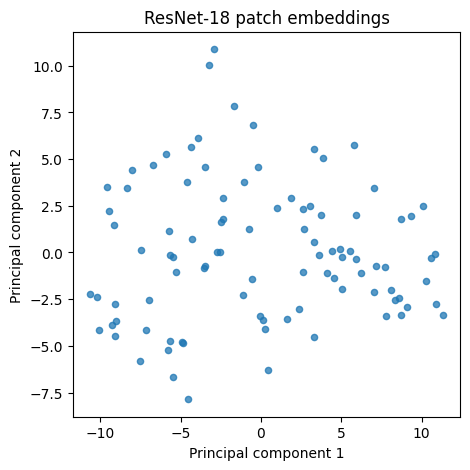

In [109]:
#21. Visualize the embeddings with PCA.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load data
embeddings = np.load(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "embeddings.npy")
metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "CMU-1_patches_metadata.csv")

# Reduce 512 features to 2 dimensions
pca = PCA(n_components=3)
embedding_2d = pca.fit_transform(embeddings)

print("PCA shape:", embedding_2d.shape)
print("Explained variance ratio", pca.explained_variance_ratio_)
print("Variance explained by three components:",
    round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(5, 5))
plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    s=20,
    alpha=0.75)

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("ResNet-18 patch embeddings")
plt.show()

# Save PCA coordinates to the metadata
metadata["PC1"] = embedding_2d[:, 0]
metadata["PC2"] = embedding_2d[:, 1]

metadata.to_csv(
  Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "patch_metadata_with_pca.csv",
  index=False)


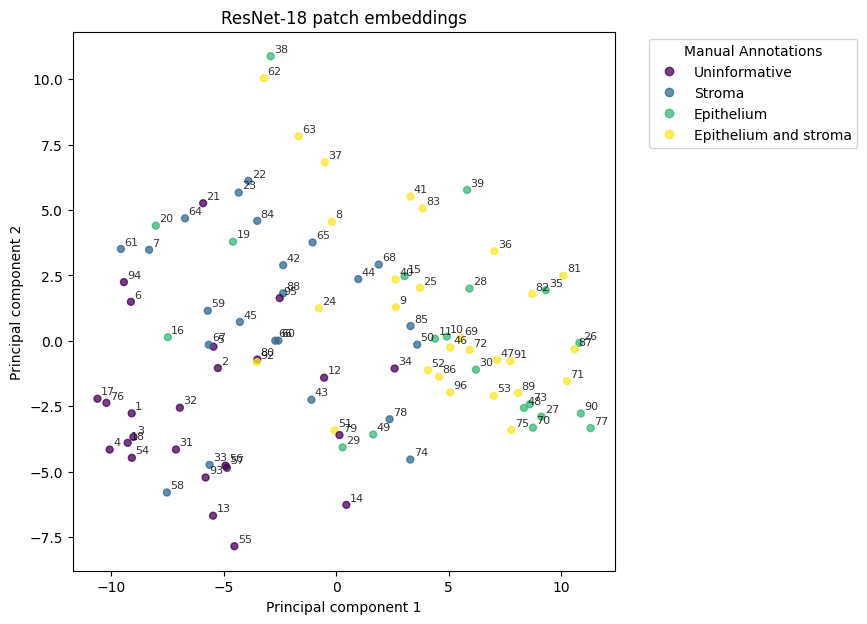

In [113]:
#22.1. Color by your own annotation.

# Manual annotation of patches:
  # Uninformative (tissue borders, artefacts, keratin) = 0.
  # Stroma (>50% patch surface) = 1.
  # Epithelium (>50% patch surface) = 2.
  # Epithelium_and_stroma = 3.

# metadata loading with PCA coordinates
metadata = pd.read_csv(Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/") / "CMU-1_patches_metadata.csv", sep=";")

plt.figure(figsize=(7, 7))
scatter = plt.scatter(
    metadata["PC1"],
    metadata["PC2"],
    c=metadata["patch_type"],
    s=25,
    alpha=0.75,
)

# Add patch_id
for idx, row in metadata.iterrows():
    plt.text(
        row["PC1"] + 0.15,  # Léger décalage en X pour la lisibilité
        row["PC2"] + 0.15,  # Léger décalage en Y
        str(idx + 1),
        fontsize=8,
        alpha=0.8
    )

labels = ["Uninformative", "Stroma", "Epithelium", "Epithelium and stroma"]

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("ResNet-18 patch embeddings")

plt.legend(handles=scatter.legend_elements()[0], labels=labels, title="Manual Annotations", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

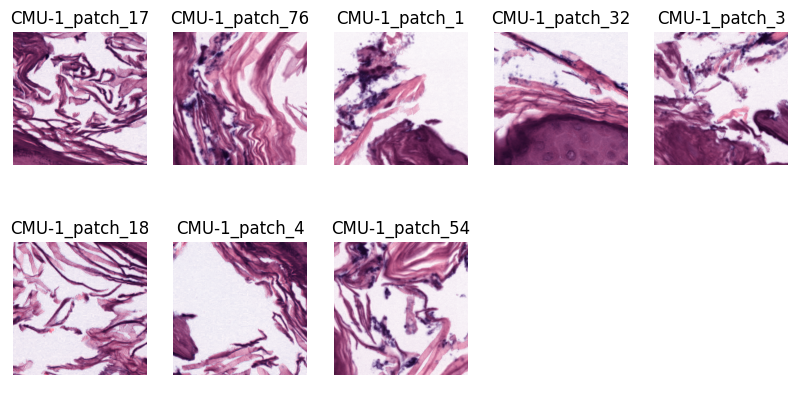

In [115]:
#22.2. Show corresponding patches.
patches = [17, 76, 1, 32, 3, 18, 4, 54]

plt.figure(figsize=(10,5))
plt.axis("off")
for img in patches:
  plt.subplot(2, int(len(patches)/2+1), patches.index(img)+1)
  plt.imshow(plt.imread(f"/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/CMU-1_patch_{img}_normed.png"))
  plt.title(f"CMU-1_patch_{img}")
  plt.axis("off")

plt.show()

In [ ]:
#23. Train a very simple classifier.


# --
#Q48. Why is random patch-level splitting potentially problematic?
#Q49. Why is patient/animal-level splitting preferable?
#Q50. If you have only one WSI, can you legitimately claim that your model generalizes to other animals?

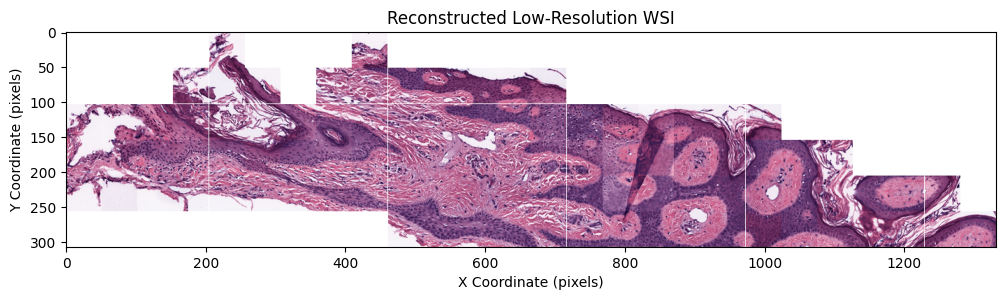

In [118]:
#22.3. Reconstruct the WSI at low resolution from patch (x, y) coordinates.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# 1. Retrieve the metadata with coordinates

# 2. Set scaling factor for low resolution (e.g., 0.1 to reduce resolution to 10%)

# Get coordinates and scale them

# Offset coordinates so that the minimum starts at 0

# 3. Calculate canvas size

# Create a blank white canvas

# 4. Paste each resized patch into the canvas

# 5. Display the low-resolution WSI canvas
